First Five Rows:
         Date Product    Sales  Quantity Region
0  2026-01-01  Laptop  50000.0         5  North
1  2026-01-02   Phone  20000.0        10  South
2  2026-01-03  Tablet  15000.0         8   East
3  2026-01-04  Laptop      NaN         4   West
4  2026-01-05   Phone  25000.0        12  North

Missing Values:
Date        0
Product     0
Sales       1
Quantity    0
Region      0
dtype: int64

Statistical Summary:
              Sales  Quantity
count     10.000000  10.00000
mean   31222.222222   7.80000
std    17209.672847   2.65832
min    15000.000000   4.00000
25%    18500.000000   6.00000
50%    23500.000000   7.50000
75%    45305.555556   9.75000
max    60000.000000  12.00000

Product Summary:
  Product          Sales  Quantity
0  Laptop  196222.222222        21
1   Phone   67000.000000        33
2  Tablet   49000.000000        24


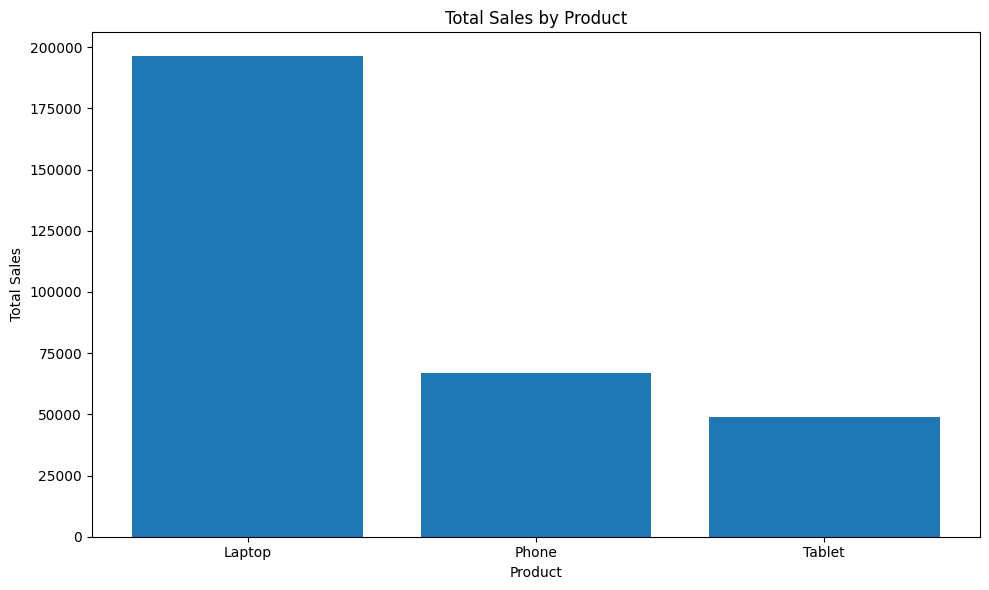

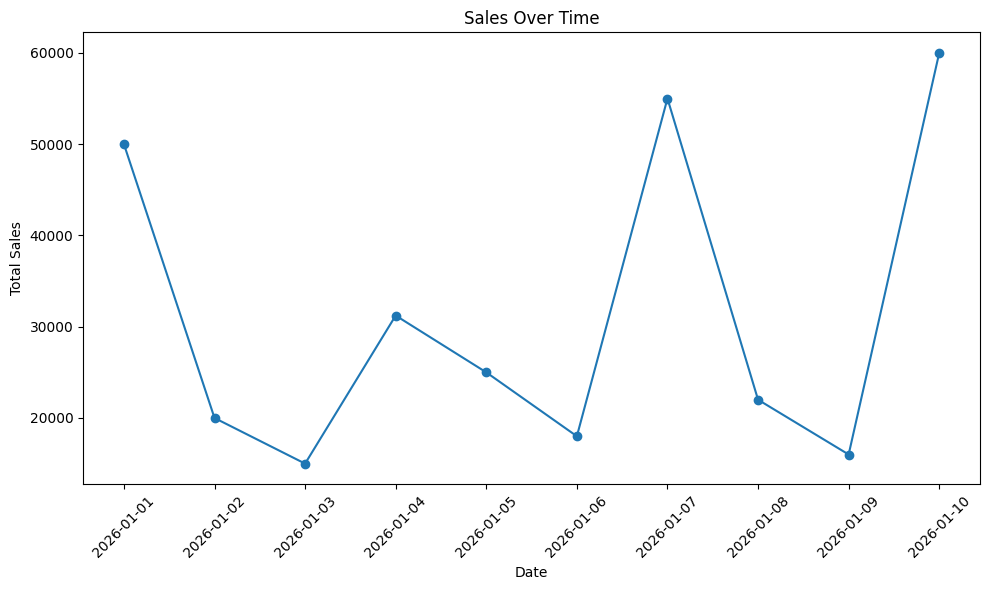


Pivot Table:
Product        Laptop    Phone   Tablet
Region                                 
East     55000.000000      0.0  15000.0
North    50000.000000  25000.0  16000.0
South    60000.000000  20000.0  18000.0
West     31222.222222  22000.0      0.0

Correlation Matrix:
           Sales  Quantity
Sales     1.0000   -0.5694
Quantity -0.5694    1.0000


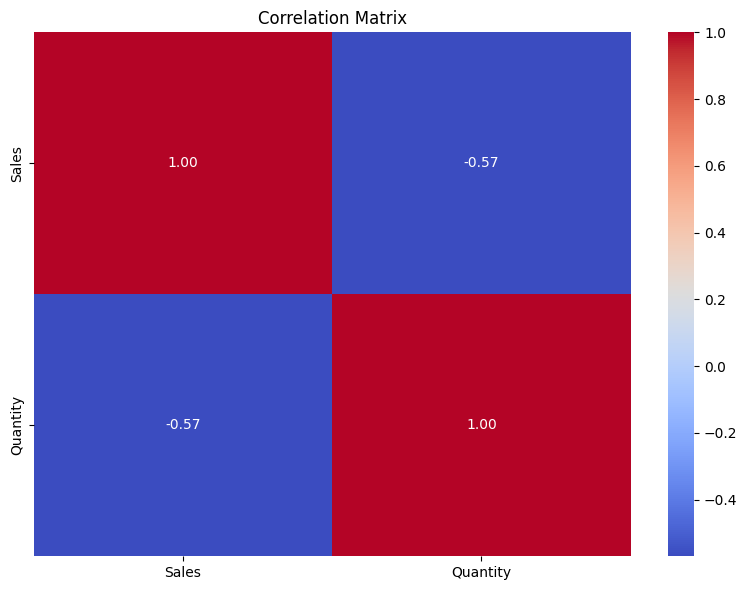

In [1]:

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

data = {
"Date": [
"2026-01-01", "2026-01-02", "2026-01-03",
"2026-01-04", "2026-01-05", "2026-01-06",
"2026-01-07", "2026-01-08", "2026-01-09",
"2026-01-10"
],
"Product": [
"Laptop", "Phone", "Tablet", "Laptop", "Phone",
"Tablet", "Laptop", "Phone", "Tablet", "Laptop"
],
"Sales": [
50000, 20000, 15000, np.nan, 25000,
18000, 55000, 22000, 16000, 60000
],
"Quantity": [
5, 10, 8, 4, 12, 9, 6, 11, 7, 6
],
"Region": [
"North", "South", "East", "West", "North",
"South", "East", "West", "North", "South"
]
}

df = pd.DataFrame(data)

print("First Five Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

df["Sales"] = df["Sales"].fillna(df["Sales"].mean())

df.dropna(
subset=["Product", "Quantity", "Region"],
inplace=True
)

print("\nStatistical Summary:")
print(df.describe())


product_summary = (
df.groupby("Product")
.agg({"Sales": "sum", "Quantity": "sum"})
.reset_index()
)

print("\nProduct Summary:")
print(product_summary)

plt.figure(figsize=(10, 6))
plt.bar(product_summary["Product"], product_summary["Sales"])
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product")
plt.tight_layout()
plt.show()



df["Date"] = pd.to_datetime(df["Date"])


sales_over_time = (
df.groupby("Date")
.agg({"Sales": "sum"})
.reset_index()
)


plt.figure(figsize=(10, 6))
plt.plot(
sales_over_time["Date"],
sales_over_time["Sales"],
marker="o"
)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title("Sales Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


pivot_table = df.pivot_table(
values="Sales",
index="Region",
columns="Product",
aggfunc="sum",
fill_value=0
)

print("\nPivot Table:")
print(pivot_table)


correlation_matrix = df.corr(numeric_only=True)

print("\nCorrelation Matrix:")
print(correlation_matrix)


plt.figure(figsize=(8, 6))
sns.heatmap(
correlation_matrix,
annot=True,
cmap="coolwarm",
fmt=".2f"
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()